# Automated Droplet Size Measurement

Measures the **horizontal** and **vertical** diameter of trapped ethanol droplets, in microns,
from still frames, using a calibration-slide image (10x10 grid of 100 um squares) taken at the
same optics to set the pixel to micron scale.

Implements the design in `CONTEXT.md` and the build spec in `INSTRUCTIONS.md`.

**How to use:** edit the **Config** cell below (normally only `DATE_DIR`, or the two folder
overrides), then Run All. Results land in `results/`:

* `measurements.csv` - one row per drop
* `qc_calibration.png` - grid-detection overlay
* `qc_drops/<image>.png` - per-drop overlay for visual audit

**Always look at the QC overlays before trusting a batch.**

---
### Notes on two deviations from `INSTRUCTIONS.md`, both found while validating on the real files

1. **Background sigma estimator.** The spec asks for `sigma = 1.4826 * MAD`. On these images the
   top-hat output is integer-quantised with a very small spread, so the MAD collapses onto a whole
   number (MAD = 1.0 exactly) and jumps in steps of 1.5 counts between images - the threshold then
   swings by ~4 counts for no physical reason. We take `sigma = max(MAD_sigma, IQR_sigma)`, which
   is the same robust idea but reads a two-point spread instead of a one-point one. It is stable
   across the sample images and lands the measurements on the acceptance targets.
2. **`MIN_PEAK_SIGMA` (new knob).** `K_SIGMA` alone sets the *edge*, and at the edge level the
   bright bands above and below the rod gap break into a few hundred JPEG/noise blobs that pass
   the area and edge-margin filters. Real drops are enormously brighter than those: on the sample
   frames drops peak at 94-157 counts above background while every noise blob peaks below 28. So a
   blob must additionally *peak* above `med + MIN_PEAK_SIGMA * sigma` to count as a drop. This is a
   detection gate only - it does not touch where the measured edge falls, which is still `K_SIGMA`.


In [10]:
# ============================== CONFIG ==============================
# The only cell the operator normally edits.

# --- Folders -------------------------------------------------------
# Convention:  DATE_DIR/drops/ , DATE_DIR/calibration/ , DATE_DIR/results/
DATE_DIR      = r"F:\Imaging\2026.09.09"
DROPS_SUBDIR  = "drops"
CALIB_SUBDIR  = "calibration"

# This dataset is not laid out in the convention above, so point at the real folders directly.
# Set either to None to fall back to DATE_DIR/<subdir>.
DROPS_DIR_OVERRIDE = r"F:\Imaging\2026.09.09\max zoom\trapping attempts"

# Calibration override: None => use this date's own calibration folder (default).
# Set to another date's calibration folder ONLY when explicitly reusing one.
CALIB_OVERRIDE_DIR = r"F:\Imaging\2026.09.09\diff calib\calib slides 2"

# Where results are written. None => DATE_DIR/results
RESULTS_DIR_OVERRIDE = None

# --- Physical constant ---------------------------------------------
BOX_UM        = 100.0     # calibration grid square = 0.1 mm = 100 um

# --- Calibration ----------------------------------------------------
CALIB_BORDER      = 2      # px of bright sensor border to trim before anything else
ANGLE_RANGE_DEG   = 8.0    # de-rotation search half-range
ANGLE_STEP_DEG    = 0.1
MIN_GRID_LINES    = 4      # fewer detected lines than this => calibration image unusable
MAX_FIT_RMS_PX    = 0.5    # warn above this
FFT_TOL           = 0.05   # warn if least-squares and FFT periods disagree by more than 5%

# --- Drop detection / measurement -----------------------------------
TOPHAT_KERNEL = 61        # odd; ellipse SE for background flatten. ~3-4x max drop diameter.
K_SIGMA       = 3.0       # THE tuning knob: edge = background + K_SIGMA * sigma
MIN_PEAK_SIGMA = 12.0     # detection gate: blob peak must exceed med + this * sigma
MIN_DROP_AREA = 20        # px; reject noise blobs smaller than this
MAX_DROP_AREA = 1500      # px; reject huge blobs (bands/artifacts)
CLOSE_ITER    = 1         # morphological close to bridge ring / two-spot gaps
CLOSE_KERNEL  = 5         # odd; ellipse SE size for that close
EDGE_MARGIN   = 8         # px; reject blobs whose bbox touches within this of the frame edge
SATURATION    = 250       # raw pixel >= this inside a blob => saturation flag
BLUR_SHARPNESS = 0.45     # boundary sharpness below this => blurry flag (soft, review only)

# --- QC overlay view -------------------------------------------------
# The full-frame panel of each drop QC overlay is cropped to this window, so the drops are not
# three specks lost in a mostly-empty frame. EDIT THESE NUMBERS FREELY.
#
#   (row0, row1, col0, col1)  in pixels of the ORIGINAL image (not of the saved overlay).
#   None for any bound  ->  run to that edge of the frame.
#   QC_VIEW_CROP = None ->  show the whole frame, as before.
#
# Crop the *view*, never the finished overlay: slicing the saved PNG cuts off the titles and
# the H x V labels with it. Drops in this dataset sit in the dark rod-gap band around rows
# 660-720 and spread across the full width, hence the default below.
# After changing this, re-run the "DROPS: run over the folder" cell to redraw the overlays.
# Any drop outside the window is still measured, and the overlay title says one is off-view.
QC_VIEW_CROP  = (600, 780, None, None)

IMAGE_EXTS    = (".jpg", ".jpeg", ".png", ".tif", ".tiff")


In [11]:
# ============================ IMPORTS & HELPERS ============================
import os, glob, math, warnings

import numpy as np
import pandas as pd
import cv2
from scipy.ndimage import binary_fill_holes, label, find_objects, uniform_filter1d
from scipy.signal import find_peaks

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Ellipse

print("numpy", np.__version__, "| cv2", cv2.__version__, "| pandas", pd.__version__)


# --------------------------------------------------------------- paths
def _resolve(override, subdir):
    return override if override else os.path.join(DATE_DIR, subdir)

DROPS_DIR   = _resolve(DROPS_DIR_OVERRIDE, DROPS_SUBDIR)
CALIB_DIR   = _resolve(CALIB_OVERRIDE_DIR, CALIB_SUBDIR)
RESULTS_DIR = RESULTS_DIR_OVERRIDE if RESULTS_DIR_OVERRIDE else os.path.join(DATE_DIR, "results")
QC_DROPS_DIR = os.path.join(RESULTS_DIR, "qc_drops")


def list_images(folder, what):
    """Every image file in `folder`, sorted naturally-ish. Raises a named error if unusable."""
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"{what} folder does not exist: {folder}")
    files = [p for p in sorted(glob.glob(os.path.join(folder, "*")))
             if os.path.splitext(p)[1].lower() in IMAGE_EXTS]
    if not files:
        raise FileNotFoundError(f"{what} folder contains no images ({IMAGE_EXTS}): {folder}")
    return files


def load_gray(path):
    """Read any image as a 2-D float32 grayscale array. Returns None if unreadable."""
    im = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if im is None:
        return None
    if im.ndim == 3:
        im = cv2.cvtColor(im[:, :, :3], cv2.COLOR_BGR2GRAY)
    if im.dtype == np.uint16:            # scale 16-bit down to the 0-255 world
        im = im.astype(np.float32) / 257.0
    return im.astype(np.float32)


def largest_true_run(mask):
    """(start, stop) of the longest contiguous run of True in a 1-D boolean array."""
    mask = np.asarray(mask, bool)
    if not mask.any():
        return 0, len(mask)
    padded = np.r_[False, mask, False]
    edges = np.flatnonzero(padded[1:] != padded[:-1])
    starts, stops = edges[0::2], edges[1::2]
    k = int(np.argmax(stops - starts))
    return int(starts[k]), int(stops[k])


def rotate_image(img, angle_deg):
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w / 2.0, h / 2.0), angle_deg, 1.0)
    return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def periodicity_score(profile, skip_bins=5):
    """Strength of the strongest non-DC periodicity in a 1-D profile."""
    p = np.asarray(profile, np.float64)
    if p.size < 16:
        return 0.0
    p = (p - p.mean()) * np.hanning(p.size)
    F = np.abs(np.fft.rfft(p))
    F[:skip_bins] = 0.0
    return float(F.max())


def fft_period(profile, skip_bins=5):
    """Period (in samples) of the strongest non-DC component. np.nan if undefined."""
    p = np.asarray(profile, np.float64)
    if p.size < 16:
        return np.nan
    p = (p - p.mean()) * np.hanning(p.size)
    F = np.abs(np.fft.rfft(p))
    F[:skip_bins] = 0.0
    k = int(np.argmax(F))
    return p.size / k if k else np.nan


def stretch_for_display(img, lo_pct=1.0, hi_pct=99.7):
    """Contrast-stretched uint8 copy, for looking at faint things."""
    lo, hi = np.percentile(img, lo_pct), np.percentile(img, hi_pct)
    if hi <= lo:
        lo, hi = float(img.min()), float(max(img.max(), img.min() + 1))
    return np.clip((img - lo) * 255.0 / (hi - lo), 0, 255).astype(np.uint8)


os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(QC_DROPS_DIR, exist_ok=True)
print("drops      :", DROPS_DIR)
print("calibration:", CALIB_DIR)
print("results    :", RESULTS_DIR)


numpy 2.2.6 | cv2 4.12.0 | pandas 2.3.3
drops      : F:\Imaging\2026.09.09\max zoom\trapping attempts
calibration: F:\Imaging\2026.09.09\diff calib\calib slides 2
results    : F:\Imaging\2026.09.09\results


In [12]:
# ======================= CALIBRATION: functions =======================
# Grid is dark lines on a bright background, visible only inside the lit ~1 mm rod gap,
# rotated by a few degrees, and speckled with non-periodic impurities. So: isolate the lit
# band, isolate the part of it that actually carries periodic structure, de-rotate, then take
# the least-squares slope of gridline-position vs gridline-index. Every line contributes, the
# fit residual is a free quality check, and the impurities (non-periodic) are ignored.


def find_grid_roi(gray):
    """Crop to the lit band x the columns that carry periodic structure.
    Returns (roi, (row0, row1), (col0, col1)) in original-image coordinates."""
    b = CALIB_BORDER
    core = gray[b:gray.shape[0] - b, b:gray.shape[1] - b]

    # 1. the lit band: the largest contiguous run of bright rows
    row_mean = core.mean(axis=1)
    row_thr = 0.5 * np.percentile(row_mean, 90)      # 0.5 x (top decile of row means)
    r0, r1 = largest_true_run(row_mean > row_thr)
    band = core[r0:r1, :]

    # 2. horizontal extent: gridlines make the column-wise spread jump. Plain bright margins
    #    and the letter labels do not. Take the largest contiguous run of elevated spread.
    col_struct = uniform_filter1d(band.std(axis=0), 15)
    col_thr = 0.5 * (np.percentile(col_struct, 90) + np.percentile(col_struct, 10))
    c0, c1 = largest_true_run(col_struct > col_thr)

    roi = band[:, c0:c1]
    return roi, (r0 + b, r1 + b), (c0 + b, c1 + b)


def derotate(roi):
    """Find the rotation that makes both gridline families most periodic.
    Returns (angle_deg, derotated_signal, hit_boundary)."""
    sig = -(roi - roi.mean())            # invert: dark lines become bright ridges

    def score(angle, half_range):
        r = rotate_image(sig, angle)
        m = int(0.06 * min(r.shape)) + 2 + int(abs(angle) / 57.3 * max(r.shape))
        m = min(m, min(r.shape) // 3)
        r = r[m:r.shape[0] - m, m:r.shape[1] - m]
        if min(r.shape) < 32:
            return -np.inf, None
        s = (periodicity_score(r.sum(axis=0)) / r.shape[0]
             + periodicity_score(r.sum(axis=1)) / r.shape[1])
        return s, r

    half = ANGLE_RANGE_DEG
    for _ in range(3):                   # widen if the optimum sits on the boundary
        angles = np.arange(-half, half + 1e-9, ANGLE_STEP_DEG)
        scores = np.array([score(a, half)[0] for a in angles])
        best = float(angles[int(np.argmax(scores))])
        if abs(abs(best) - half) > 1.5 * ANGLE_STEP_DEG:
            return best, score(best, half)[1], False
        warnings.warn(f"de-rotation optimum {best:+.2f} deg hit the +-{half:.1f} deg search "
                      f"boundary; widening")
        half *= 2
    return best, score(best, half)[1], True


def spacing_from_profile(profile, axis_name):
    """Least-squares px-per-box from the peak positions of a 1-D line profile.
    Returns dict(px_per_box, rms, n_lines, peaks, fft_period, warnings)."""
    out = {"axis": axis_name, "peaks": np.array([]), "px_per_box": np.nan, "good": False,
           "rms": np.nan, "n_lines": 0, "fft_period": np.nan, "warnings": []}
    T = fft_period(profile)
    out["fft_period"] = T
    dist = max(3, int(0.6 * T)) if np.isfinite(T) else 3
    peaks, _ = find_peaks(profile, distance=dist, prominence=0.4 * profile.std())
    out["peaks"] = peaks
    out["n_lines"] = len(peaks)
    if len(peaks) < MIN_GRID_LINES:
        out["warnings"].append(f"{axis_name}: only {len(peaks)} gridlines found "
                               f"(need {MIN_GRID_LINES})")
        return out

    idx = np.arange(len(peaks), dtype=float)
    A = np.vstack([idx, np.ones_like(idx)]).T
    slope, intercept = np.linalg.lstsq(A, peaks.astype(float), rcond=None)[0]
    resid = peaks - (A @ np.array([slope, intercept]))
    out["px_per_box"] = float(slope)
    out["rms"] = float(np.sqrt(np.mean(resid ** 2)))
    out["good"] = out["rms"] <= MAX_FIT_RMS_PX

    if not out["good"]:
        out["warnings"].append(f"{axis_name}: fit RMS {out['rms']:.2f} px "
                               f"> {MAX_FIT_RMS_PX} px - lines not evenly spaced, axis rejected")
    if np.isfinite(T):
        # The FFT routinely locks onto the 2nd harmonic of this grid, so compare against the
        # harmonics too and only warn when nothing lines up.
        ratios = [T * m for m in (0.5, 1, 2, 3)] + [T / m for m in (2, 3)]
        if min(abs(r - slope) for r in ratios) / slope > FFT_TOL:
            out["warnings"].append(f"{axis_name}: least-squares {slope:.2f} px/box vs FFT "
                                   f"{T:.2f} px disagree by >{FFT_TOL:.0%}, and not by a simple "
                                   f"harmonic (the least-squares fit is authoritative)")
    return out


def measure_calibration_image(path):
    """One calibration image -> per-axis scale. Returns a dict (ok=False if unusable)."""
    gray = load_gray(path)
    if gray is None:
        return {"path": path, "ok": False, "warnings": [f"unreadable image: {path}"]}

    roi, rows, cols = find_grid_roi(gray)
    if min(roi.shape) < 64:
        return {"path": path, "ok": False,
                "warnings": [f"grid ROI too small ({roi.shape}) in {os.path.basename(path)}"]}

    angle, rot, hit_edge = derotate(roi)
    col_profile = rot.sum(axis=0)        # vertical lines -> X scale
    row_profile = rot.sum(axis=1)        # horizontal lines -> Y scale
    fx = spacing_from_profile(col_profile, "X")
    fy = spacing_from_profile(row_profile, "Y")

    ok = fx["n_lines"] >= MIN_GRID_LINES and fy["n_lines"] >= MIN_GRID_LINES
    res = {
        "path": path, "name": os.path.basename(path), "ok": ok,
        "angle_deg": angle, "roi_rows": rows, "roi_cols": cols,
        "roi": roi, "rot": rot, "col_profile": col_profile, "row_profile": row_profile,
        "x": fx, "y": fy,
        "px_per_box_x": fx["px_per_box"], "px_per_box_y": fy["px_per_box"],
        "scale_x_um_per_px": BOX_UM / fx["px_per_box"] if ok else np.nan,
        "scale_y_um_per_px": BOX_UM / fy["px_per_box"] if ok else np.nan,
        "warnings": fx["warnings"] + fy["warnings"],
    }
    if ok:
        dx, dy = fx["px_per_box"], fy["px_per_box"]
        if abs(dx - dy) / (0.5 * (dx + dy)) > 0.03:
            res["warnings"].append(
                f"X and Y scales differ by {abs(dx-dy)/(0.5*(dx+dy)):.1%} "
                f"({dx:.2f} vs {dy:.2f} px/box) - non-square pixels or distortion?")
    return res


def save_calibration_qc(res, out_path):
    """De-rotated grid ROI with the fitted line positions drawn on it."""
    rot, fx, fy = res["rot"], res["x"], res["y"]
    fig, ax = plt.subplots(figsize=(9, 9 * rot.shape[0] / max(rot.shape[1], 1) + 1.2))
    ax.imshow(rot, cmap="gray")
    for p in fx["peaks"]:
        ax.axvline(p, color="#e8590c", lw=0.8, alpha=0.9)
    for p in fy["peaks"]:
        ax.axhline(p, color="#1c7ed6", lw=0.8, alpha=0.9)
    ax.set_title(
        f"{res['name']}   de-rotated {res['angle_deg']:+.2f} deg\n"
        f"X: {fx['px_per_box']:.2f} px/100um = {BOX_UM/fx['px_per_box']:.4f} um/px "
        f"({fx['n_lines']} lines, RMS {fx['rms']:.2f} px)\n"
        f"Y: {fy['px_per_box']:.2f} px/100um = {BOX_UM/fy['px_per_box']:.4f} um/px "
        f"({fy['n_lines']} lines, RMS {fy['rms']:.2f} px)",
        fontsize=10)
    ax.set_xlabel("orange = vertical gridlines (X scale)     blue = horizontal gridlines (Y scale)",
                  fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout()
    fig.savefig(out_path, dpi=130)
    return fig


def calibrate_folder(folder):
    """Measure every calibration image in `folder`; report the median scale per axis."""
    files = list_images(folder, "Calibration")
    results, bad = [], []
    for p in files:
        try:
            r = measure_calibration_image(p)
        except Exception as exc:                       # never let one bad file kill the batch
            bad.append(f"{os.path.basename(p)}: {type(exc).__name__}: {exc}")
            continue
        (results if r["ok"] else bad).append(r if r["ok"] else
                                             f"{os.path.basename(p)}: " + "; ".join(r["warnings"]))
    if not results:
        raise RuntimeError(
            "No usable calibration image found in:\n  " + folder +
            "\nProblems:\n  " + "\n  ".join(map(str, bad)) +
            "\n(The pipeline will not fall back to a hard-coded scale.)")

    # Each axis is accepted or rejected on its own fit quality: a slide can give a clean X and a
    # ragged Y (the horizontal lines sit near the edges of the lit band, where they fade out).
    def axis_median(axis):
        good = [r for r in results if r[axis]["good"]]
        used = good if good else results
        if not good:
            warnings.warn(f"no calibration image passed the RMS check on {axis.upper()}; "
                          f"falling back to all {len(results)} - check qc_calibration.png")
        v = np.array([BOX_UM / r[axis]["px_per_box"] for r in used])
        return float(np.median(v)), float(v.max() - v.min()), len(used)

    mx, spx, nx = axis_median("x")
    my, spy, ny = axis_median("y")
    summary = {
        "folder": folder, "n_images": len(results), "n_failed": len(bad), "failures": bad,
        "scale_x_um_per_px": mx, "scale_y_um_per_px": my,
        "spread_x_um_per_px": spx, "spread_y_um_per_px": spy,
        "n_used_x": nx, "n_used_y": ny,
        "per_image": results,
    }
    summary["px_per_100um_x"] = BOX_UM / summary["scale_x_um_per_px"]
    summary["px_per_100um_y"] = BOX_UM / summary["scale_y_um_per_px"]
    return summary


calibration source : F:\Imaging\2026.09.09\diff calib\calib slides 2
usable images      : 8  (failed: 4)
   !  20260909_PT_cam_10.png: X: only 3 gridlines found (need 4); Y: only 1 gridlines found (need 4)
   !  20260909_PT_cam_11.png: X: only 3 gridlines found (need 4); Y: only 1 gridlines found (need 4)
   !  20260909_PT_cam_12.png: X: fit RMS 4.79 px > 0.5 px - lines not evenly spaced, axis rejected; X: least-squares 26.94 px/box vs FFT 33.00 px disagree by >5%, and not by a simple harmonic (the least-squares fit is authoritative); Y: only 2 gridlines found (need 4)
   !  20260909_PT_cam_13.png: X: fit RMS 11.35 px > 0.5 px - lines not evenly spaced, axis rejected; X: least-squares 37.60 px/box vs FFT 17.45 px disagree by >5%, and not by a simple harmonic (the least-squares fit is authoritative); Y: only 1 gridlines found (need 4)

  X :   41.36 px / 100 um   ->  2.4179 um/px   (median of 8, spread 0.0088)
  Y :   40.87 px / 100 um   ->  2.4468 um/px   (median of 6, spread 0.0114)



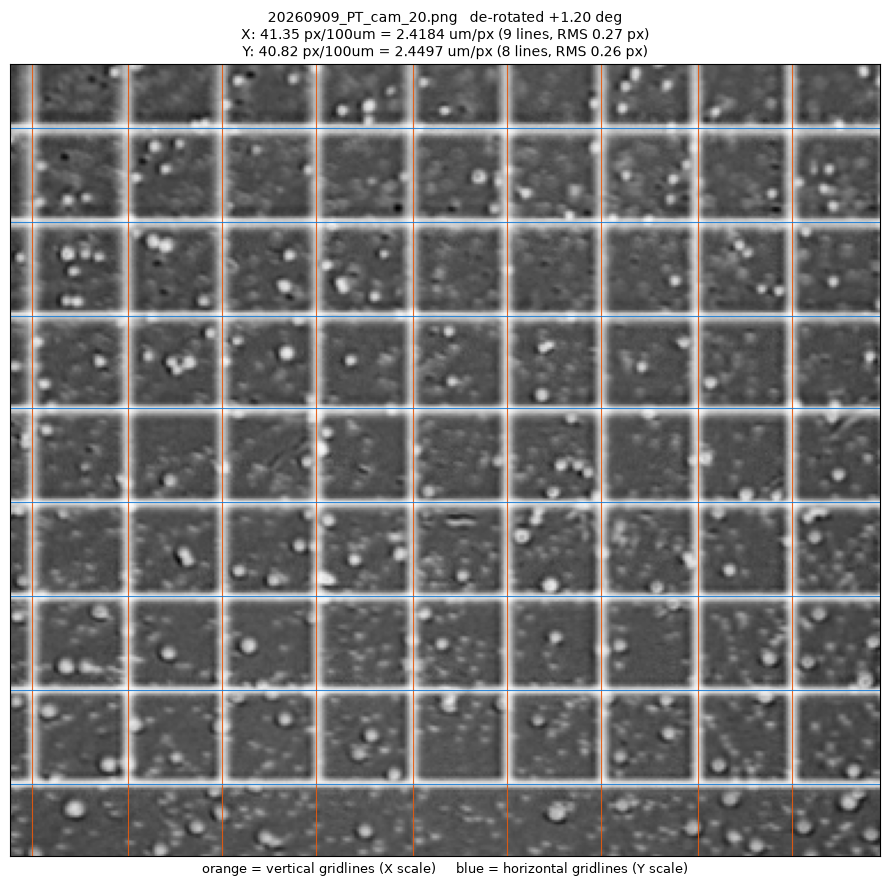

In [13]:
# ======================= CALIBRATION: run =======================
CALIB = calibrate_folder(CALIB_DIR)

print(f"calibration source : {CALIB['folder']}")
print(f"usable images      : {CALIB['n_images']}  (failed: {CALIB['n_failed']})")
for f in CALIB["failures"]:
    print("   ! ", f)
print()
print(f"  X : {CALIB['px_per_100um_x']:7.2f} px / 100 um   ->  "
      f"{CALIB['scale_x_um_per_px']:.4f} um/px   "
      f"(median of {CALIB['n_used_x']}, spread {CALIB['spread_x_um_per_px']:.4f})")
print(f"  Y : {CALIB['px_per_100um_y']:7.2f} px / 100 um   ->  "
      f"{CALIB['scale_y_um_per_px']:.4f} um/px   "
      f"(median of {CALIB['n_used_y']}, spread {CALIB['spread_y_um_per_px']:.4f})")
print()
print(f"{'image':<34}{'angle':>8}{'X px/box':>10}{'rmsX':>7}{'Y px/box':>10}{'rmsY':>7}   used")
for r in CALIB["per_image"]:
    used = ("X" if r["x"]["good"] else "-") + ("Y" if r["y"]["good"] else "-")
    print(f"{r['name']:<34}{r['angle_deg']:+8.2f}{r['px_per_box_x']:10.2f}{r['x']['rms']:7.2f}"
          f"{r['px_per_box_y']:10.2f}{r['y']['rms']:7.2f}   {used}")
    for w in r["warnings"]:
        print("      warn:", w)

# QC overlay: the image whose accepted scales sit closest to the adopted medians.
def _closeness(r):
    d = 0.0
    d += abs(r["scale_x_um_per_px"] - CALIB["scale_x_um_per_px"]) if r["x"]["good"] else 1e3
    d += abs(r["scale_y_um_per_px"] - CALIB["scale_y_um_per_px"]) if r["y"]["good"] else 1e3
    return d

_best = min(CALIB["per_image"], key=_closeness)
_qc_path = os.path.join(RESULTS_DIR, "qc_calibration.png")
_fig = save_calibration_qc(_best, _qc_path)
print("\nsaved", _qc_path, f"(from {_best['name']})")
plt.show()


In [14]:
# ======================= DROPS: functions =======================
# A global brightness threshold does NOT work on these frames - the horizontal banding from the
# rod gap dominates any single cut. Flatten first (white top-hat), then threshold relative to the
# flattened background's own noise. Drops are rings with a dark centre plus two bright specular
# spots, so fill holes and close before measuring extent.

_TOPHAT_SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (TOPHAT_KERNEL, TOPHAT_KERNEL))
_CLOSE_SE  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (CLOSE_KERNEL, CLOSE_KERNEL))


def flatten(raw):
    """White top-hat: removes the smooth horizontal banding, leaves the small bright drops."""
    return raw - cv2.morphologyEx(raw, cv2.MORPH_OPEN, _TOPHAT_SE)


def background_stats(flat):
    """Robust (median, sigma) of the flattened background, drops excluded.

    sigma is the larger of the MAD- and IQR-based robust scales. The MAD alone collapses onto a
    whole number on these integer-quantised top-hat images (see the deviations note at the top)."""
    v = flat.ravel()
    lo = v[v <= np.percentile(v, 95)]            # drop the top 5% = the drops themselves
    med = float(np.median(lo))
    mad_sigma = 1.4826 * float(np.median(np.abs(lo - med)))
    iqr_sigma = float(np.percentile(lo, 75) - np.percentile(lo, 25)) / 1.349
    return med, max(mad_sigma, iqr_sigma, 1e-6)


def _refine_edges(profile, i_first, i_last, level):
    """Sub-pixel extent along one line.

    `i_first`/`i_last` are the first and last blob pixels on that line; each is pushed outward to
    where the flattened profile crosses `level`, by linear interpolation between the two
    straddling pixels. Anchoring on the blob (rather than on the profile's maximum) keeps this
    stable for a ring: the centre column runs through the dark gap between the two bright spots,
    where a maximum-seeking walk would stop early and halve the vertical diameter."""
    n = len(profile)
    if i_first > 0 and profile[i_first - 1] < level <= profile[i_first]:
        left = i_first - (profile[i_first] - level) / (profile[i_first] - profile[i_first - 1])
    else:
        left = i_first - 0.5
    if i_last < n - 1 and profile[i_last + 1] < level <= profile[i_last]:
        right = i_last + (profile[i_last] - level) / (profile[i_last] - profile[i_last + 1])
    else:
        right = i_last + 0.5
    return float(left), float(right)


def measure_drops(path):
    """Detect and measure every drop in one image.

    Returns (list_of_drop_dicts, diagnostics). Diagnostics carries the arrays the QC overlay needs.

    Nothing in this path rotates, warps or resizes the image: the drop is measured on the pixel
    grid it was captured on. (cv2.warpAffine appears only in the calibration de-rotation.)
    """
    raw = load_gray(path)
    if raw is None:
        raise IOError(f"could not read {path}")
    Himg, Wimg = raw.shape

    flat = flatten(raw)
    med, sigma = background_stats(flat)
    level = med + K_SIGMA * sigma            # where the drop edge is called
    seed = med + MIN_PEAK_SIGMA * sigma      # how bright a blob must peak to *be* a drop

    mask = binary_fill_holes(flat > level)                      # fill the dark ring centre
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_CLOSE,
                            _CLOSE_SE, iterations=CLOSE_ITER)   # bridge the two-spot gap
    mask = binary_fill_holes(mask.astype(bool))

    labels, n_comp = label(mask)
    gx = cv2.Sobel(flat, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(flat, cv2.CV_32F, 0, 1, ksize=3)
    grad = np.hypot(gx, gy)

    drops = []
    for i, sl in enumerate(find_objects(labels)):
        if sl is None:
            continue
        comp = (labels[sl] == i + 1)
        area = int(comp.sum())
        if area < MIN_DROP_AREA or area > MAX_DROP_AREA:
            continue
        y0, y1 = sl[0].start, sl[0].stop
        x0, x1 = sl[1].start, sl[1].stop
        if (x0 < EDGE_MARGIN or y0 < EDGE_MARGIN
                or x1 > Wimg - EDGE_MARGIN or y1 > Himg - EDGE_MARGIN):
            continue                                    # frame-edge band artifact
        peak = float(flat[sl][comp].max())
        if peak < seed:
            continue                                    # noise speck, not a drop

        ys, xs = np.nonzero(comp)
        cy = y0 + float(ys.mean())
        cx = x0 + float(xs.mean())

        full = np.zeros((Himg, Wimg), bool)
        full[sl][comp] = True
        r, c = int(round(cy)), int(round(cx))
        row_idx = np.flatnonzero(full[r, :])
        col_idx = np.flatnonzero(full[:, c])
        hl, hr = _refine_edges(flat[r, :], row_idx[0], row_idx[-1], level)
        vt, vb = _refine_edges(flat[:, c], col_idx[0], col_idx[-1], level)

        contours, _ = cv2.findContours(full.astype(np.uint8), cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_NONE)
        cnt = max(contours, key=cv2.contourArea)
        if len(cnt) >= 5:
            (ex, ey), (minor, major), eang = cv2.fitEllipse(cnt)
        else:
            (ex, ey), (minor, major), eang = (cx, cy), (np.nan, np.nan), np.nan

        boundary = full.astype(np.uint8) - cv2.erode(full.astype(np.uint8), np.ones((3, 3), np.uint8))
        sharpness = float(grad[boundary > 0].mean()) / peak if peak > 0 else 0.0

        drops.append({
            "centroid_x": cx, "centroid_y": cy, "area_px": area,
            "bbox": (x0, y0, x1, y1),
            "H_px": int(x1 - x0), "V_px": int(y1 - y0),
            "H_px_subpx": hr - hl, "V_px_subpx": vb - vt,
            "ellipse_major_px": float(major), "ellipse_minor_px": float(minor),
            "ellipse": ((ex, ey), (minor, major), eang),
            "peak_flat": peak, "peak_sigma": (peak - med) / sigma,
            "sharpness": sharpness,
            "saturated": bool(raw[sl][comp].max() >= SATURATION),
            "blurry": bool(sharpness < BLUR_SHARPNESS),
        })

    drops.sort(key=lambda d: (d["centroid_x"], d["centroid_y"]))
    for j, d in enumerate(drops):
        d["drop_index"] = j

    diag = {"raw": raw, "flat": flat, "med": med, "sigma": sigma,
            "level": level, "seed": seed, "n_components": n_comp}
    return drops, diag


def view_window(shape, crop):
    """QC_VIEW_CROP -> (row_slice, col_slice), clipped to the image. None means 'to the edge'."""
    H, W = shape
    if not crop:
        return slice(0, H), slice(0, W)
    r0, r1, c0, c1 = crop
    r0 = 0 if r0 is None else int(np.clip(r0, 0, H - 1))
    r1 = H if r1 is None else int(np.clip(r1, r0 + 1, H))
    c0 = 0 if c0 is None else int(np.clip(c0, 0, W - 1))
    c1 = W if c1 is None else int(np.clip(c1, c0 + 1, W))
    return slice(r0, r1), slice(c0, c1)


def save_drop_qc(path, drops, diag, scale_x, scale_y, out_path):
    """Full-frame view with every drop boxed, plus a magnified panel per drop. The operator's
    audit surface: dust, blur, and merge/split errors all have to be visible here.

    The full-frame view is cropped to QC_VIEW_CROP. The crop is applied to the image data, so
    the titles and the per-drop labels are laid out around it and never clipped.

    Every panel is drawn with aspect='equal' and the per-drop insets use a SQUARE crop window,
    so the display cannot stretch a drop: shape seen here is shape in the data. All of this is
    display only - none of it feeds the measurement."""
    raw = diag["raw"]
    disp = stretch_for_display(raw)
    vy, vx = view_window(raw.shape, QC_VIEW_CROP)
    view = disp[vy, vx]
    off_view = [d for d in drops
                if not (vx.start <= d["centroid_x"] < vx.stop
                        and vy.start <= d["centroid_y"] < vy.stop)]

    n = len(drops)
    ncol = max(n, 1)
    vh, vw = view.shape
    if vw >= vh:                    # wide strip: view across the top, zoom panels in a row below
        figw = max(11.0, 2.9 * ncol)
        view_h = figw * vh / vw
        fig = plt.figure(figsize=(figw, view_h + 4.6), layout="constrained")
        gs = fig.add_gridspec(2, ncol, height_ratios=[max(view_h, 1.2), 3.1])
        axf = fig.add_subplot(gs[0, :])
        axes = [fig.add_subplot(gs[1, j]) for j in range(n)]
    else:                           # tall frame: view on the left, zoom panels stacked at right
        fig = plt.figure(figsize=(6 + 2.6 * ncol, 8.2), layout="constrained")
        gs = fig.add_gridspec(ncol, 2, width_ratios=[3, 2.0])
        axf = fig.add_subplot(gs[:, 0])
        axes = [fig.add_subplot(gs[j, 1]) for j in range(n)]

    # aspect="equal" is matplotlib's default for imshow; stated explicitly here and on the insets
    # so a future edit cannot quietly switch it to "auto", which stretches pixels to fill the axes.
    axf.imshow(view, cmap="gray", vmin=0, vmax=255, aspect="equal")
    _crop_note = ("full frame" if not QC_VIEW_CROP else
                  f"view rows {vy.start}-{vy.stop}, cols {vx.start}-{vx.stop} (QC_VIEW_CROP)")
    axf.set_title(f"{os.path.basename(path)}\n{n} drop(s)   "
                  f"bkg={diag['med']:.1f}  sigma={diag['sigma']:.2f}  "
                  f"edge level={diag['level']:.1f}\n{_crop_note}", fontsize=9)
    axf.set_xticks([]); axf.set_yticks([])
    if off_view:
        axf.set_xlabel(f"!! {len(off_view)} measured drop(s) outside this view "
                       f"- widen QC_VIEW_CROP to audit them",
                       fontsize=9, color="#c92a2a")

    for d in drops:
        if d in off_view:
            continue
        x0, y0, x1, y1 = d["bbox"]
        pad = 22
        axf.add_patch(Rectangle((x0 - vx.start - pad, y0 - vy.start - pad),
                                (x1 - x0) + 2 * pad, (y1 - y0) + 2 * pad,
                                fill=False, ec="#e8590c", lw=1.1))
        axf.text(x0 - vx.start - pad, y0 - vy.start - pad - 6,
                 str(d["drop_index"]), color="#e8590c", fontsize=9)

    for j, d in enumerate(drops):
        x0, y0, x1, y1 = d["bbox"]
        pad = 18
        # SQUARE inset window, centred on the drop centroid: the same +-half pixels in x and in
        # y. A window sized off the bbox is wider than it is tall for exactly the drops whose
        # roundness is in question, which invites reading the framing as the drop's shape. If
        # the square would run off the frame it is shrunk symmetrically, never made oblong.
        cx_i, cy_i = int(round(d["centroid_x"])), int(round(d["centroid_y"]))
        half = int(np.ceil(max(x1 - x0, y1 - y0) / 2)) + pad
        half = max(1, min(half, cx_i, cy_i,
                          raw.shape[1] - 1 - cx_i, raw.shape[0] - 1 - cy_i))
        sy = slice(cy_i - half, cy_i + half + 1)
        sx = slice(cx_i - half, cx_i + half + 1)
        ax = axes[j]
        # interpolation="nearest": at ~55 px across, the default smoothing blurs the very edge
        # the operator is being asked to judge.
        ax.imshow(stretch_for_display(diag["flat"][sy, sx], 2, 99.5), cmap="gray",
                  aspect="equal", interpolation="nearest")
        ox, oy = sx.start, sy.start
        ax.add_patch(Rectangle((x0 - ox - 0.5, y0 - oy - 0.5), x1 - x0, y1 - y0,
                               fill=False, ec="#e8590c", lw=1.0))
        (ex, ey), (mn, mj), ang = d["ellipse"]
        if np.isfinite(mj):
            ax.add_patch(Ellipse((ex - ox, ey - oy), mn, mj, angle=ang,
                                 fill=False, ec="#1c7ed6", lw=1.0, ls="--"))
        flags = "".join([" SAT" if d["saturated"] else "", " BLUR" if d["blurry"] else ""])
        ax.set_title(
            f"#{d['drop_index']}  H {d['H_px_subpx']:.1f}px = {d['H_px_subpx']*scale_x:.1f}um\n"
            f"V {d['V_px_subpx']:.1f}px = {d['V_px_subpx']*scale_y:.1f}um\n"
            f"sharp {d['sharpness']:.2f}{flags}",
            fontsize=8, color=("#c92a2a" if flags else "#212529"))
        ax.set_xticks([]); ax.set_yticks([])

    fig.savefig(out_path, dpi=120, bbox_inches="tight")
    plt.close(fig)


print("drop functions ready")


drop functions ready


In [15]:
# ======================= DROPS: run over the folder =======================
drop_files = list_images(DROPS_DIR, "Drops")
print(f"{len(drop_files)} image(s) in {DROPS_DIR}\n")

scale_x = CALIB["scale_x_um_per_px"]
scale_y = CALIB["scale_y_um_per_px"]

rows = []
for path in drop_files:
    name = os.path.basename(path)
    try:
        drops, diag = measure_drops(path)
    except Exception as exc:
        print(f"  ! skipping {name}: {type(exc).__name__}: {exc}")
        continue

    save_drop_qc(path, drops, diag, scale_x, scale_y,
                 os.path.join(QC_DROPS_DIR, os.path.splitext(name)[0] + ".png"))

    if not drops:
        rows.append({"image": name, "drop_index": np.nan, "n_drops": 0})
        print(f"  {name:<48} 0 drops")
        continue

    for d in drops:
        rows.append({
            "image": name, "drop_index": d["drop_index"], "n_drops": len(drops),
            "centroid_x": d["centroid_x"], "centroid_y": d["centroid_y"],
            "H_px": d["H_px"], "V_px": d["V_px"],
            "H_px_subpx": d["H_px_subpx"], "V_px_subpx": d["V_px_subpx"],
            "ellipse_major_px": d["ellipse_major_px"],
            "ellipse_minor_px": d["ellipse_minor_px"],
            "saturated": d["saturated"], "blurry": d["blurry"],
            "peak_sigma": d["peak_sigma"], "sharpness": d["sharpness"],
        })
    print(f"  {name:<48} {len(drops)} drop(s): " + ", ".join(
        f"#{d['drop_index']} {d['H_px_subpx']:.1f}x{d['V_px_subpx']:.1f}px"
        + ("[BLUR]" if d["blurry"] else "") + ("[SAT]" if d["saturated"] else "")
        for d in drops))

print(f"\nQC overlays -> {QC_DROPS_DIR}")


6 image(s) in F:\Imaging\2026.09.09\max zoom\trapping attempts

  20260909_PT_cam_0_diffcalib_frame148.jpg         2 drop(s): #0 18.5x14.9px, #1 20.2x15.1px[BLUR]
  20260909_PT_cam_0_diffcalib_frame152.jpg         1 drop(s): #0 17.0x12.9px
  20260909_PT_cam_0_diffcalib_frame163.jpg         1 drop(s): #0 12.6x9.4px
  20260909_PT_cam_0_diffcalib_frame372.jpg         3 drop(s): #0 16.7x13.9px, #1 22.2x14.9px[BLUR], #2 17.4x12.4px
  20260909_PT_cam_0_diffcalib_frame378j.jpg        2 drop(s): #0 14.3x12.8px, #1 13.2x10.3px
  20260909_PT_cam_0_diffcalib_frame379.jpg         1 drop(s): #0 15.7x12.1px

QC overlays -> F:\Imaging\2026.09.09\results\qc_drops


In [ ]:
# ======================= CONVERSION + RESULTS TABLE =======================
df = pd.DataFrame(rows)

df["H_um"] = df["H_px_subpx"] * scale_x
df["V_um"] = df["V_px_subpx"] * scale_y
df["mean_um"] = (df["H_um"] + df["V_um"]) / 2.0
df["scale_x_um_per_px"] = scale_x
df["scale_y_um_per_px"] = scale_y
df["calib_source"] = CALIB["folder"]
df["k_sigma"] = K_SIGMA
df["tophat_kernel"] = TOPHAT_KERNEL

COLUMNS = ["image", "drop_index", "n_drops", "centroid_x", "centroid_y",
           "H_px", "V_px", "H_px_subpx", "V_px_subpx",
           "ellipse_major_px", "ellipse_minor_px",
           "H_um", "V_um", "mean_um",
           "scale_x_um_per_px", "scale_y_um_per_px", "calib_source",
           "saturated", "blurry", "k_sigma", "tophat_kernel"]
for c in COLUMNS:
    if c not in df.columns:
        df[c] = np.nan
df = df[COLUMNS + [c for c in ("peak_sigma", "sharpness") if c in df.columns]]
df = df.sort_values(["image", "drop_index"], na_position="last").reset_index(drop=True)

csv_path = os.path.join(RESULTS_DIR, "measurements.csv")
df.to_csv(csv_path, index=False)
print("wrote", csv_path, f"({len(df)} rows)")

with pd.option_context("display.width", 220, "display.max_columns", 40,
                       "display.float_format", lambda v: f"{v:.3f}"):
    display(df[["image", "drop_index", "n_drops", "H_px_subpx", "V_px_subpx",
                "H_um", "V_um", "mean_um", "saturated", "blurry"]])


wrote F:\Imaging\2026.09.09\results\measurements.csv (10 rows)


,image,drop_index,n_drops,H_px_subpx,V_px_subpx,H_um,V_um,mean_um,saturated,blurry
0,20260909_PT_cam_0_diffcalib_frame148.jpg,0,2,18.534,14.906,44.814,36.473,40.643,False,False
1,20260909_PT_cam_0_diffcalib_frame148.jpg,1,2,20.166,15.078,48.758,36.893,42.826,False,True
2,20260909_PT_cam_0_diffcalib_frame152.jpg,0,1,16.961,12.937,41.010,31.654,36.332,False,False
3,20260909_PT_cam_0_diffcalib_frame163.jpg,0,1,12.641,9.397,30.564,22.994,26.779,False,False
4,20260909_PT_cam_0_diffcalib_frame372.jpg,0,3,16.707,13.939,40.396,34.106,37.251,False,False
5,20260909_PT_cam_0_diffcalib_frame372.jpg,1,3,22.190,14.898,53.652,36.454,45.053,False,True
6,20260909_PT_cam_0_diffcalib_frame372.jpg,2,3,17.420,12.404,42.120,30.351,36.236,False,False
7,20260909_PT_cam_0_diffcalib_frame378j.jpg,0,2,14.297,12.795,34.568,31.306,32.937,False,False
8,20260909_PT_cam_0_diffcalib_frame378j.jpg,1,2,13.164,10.331,31.829,25.279,28.554,False,False
9,20260909_PT_cam_0_diffcalib_frame379.jpg,0,1,15.677,12.064,37.906,29.520,33.713,False,False


## Tuning guide

`K_SIGMA` is the knob. It sets where the drop edge is called: `edge = background + K_SIGMA * sigma`
on the flattened image. Set it once so a clear drop reproduces a trusted horizontal number, then
**hold it fixed** for everything that will be compared or pooled.

| symptom | what to change |
|---|---|
| drops read **too small**, or are not detected at all | lower `K_SIGMA` (try 2.5); check the frame is not saturated; confirm `TOPHAT_KERNEL` is comfortably larger than the drop |
| **noise specks** picked up as drops | raise `K_SIGMA`, `MIN_DROP_AREA`, or `MIN_PEAK_SIGMA` |
| one drop's two spots become **two blobs** | raise `CLOSE_ITER`, `CLOSE_KERNEL`, or `TOPHAT_KERNEL` slightly |
| two real drops **merge** into one | lower `CLOSE_ITER`; there is no reliable automatic split - use the QC overlay and discard |
| a sharp drop is flagged **BLUR** (or a soft one is not) | adjust `BLUR_SHARPNESS`; it is a soft review flag, never a rejection |

**Things not to do**

* Do not re-tune `K_SIGMA` to make the vertical diameters match old hand-measured verticals.
  Hand-measured verticals are systematically **large**: vertical contrast is low, so by eye the
  shallow shoulders of the profile - only a few counts above background - get included. The
  automation cuts at the true separation from background. Re-tuning `k` to close that gap would be
  fitting to a known eyeballing error. Horizontal numbers and the calibration have no such offset.
* **Do not plot old manual vertical diameters and new automated vertical diameters on the same
  curve.** There is a definitional offset between them. Re-run the old images through this
  pipeline to make them comparable.
* Do not average the X and Y scales into one. They are kept separate on purpose; a large
  difference between them is a useful warning about non-square pixels or distortion.
* Do not reuse a calibration across days unless you deliberately mean to - set `CALIB_OVERRIDE_DIR`
  and check `calib_source` in the CSV afterwards.

**Operating constraints**

* Keep exposure and lighting consistent within any set of drops that will be compared or pooled.
  `K_SIGMA` is relative to the noise so it self-adapts to modest changes, but after a large change
  glance at a clear drop's QC overlay.
* **Never saturate the drops.** Once pixels clip at 255 the true edge is gone and no threshold
  recovers it. Saturated drops are flagged, but the measurement is not trustworthy - retake them.
* Prefer PNG or TIFF over JPEG. JPEG block artifacts are worst exactly at these faint,
  low-contrast edges.


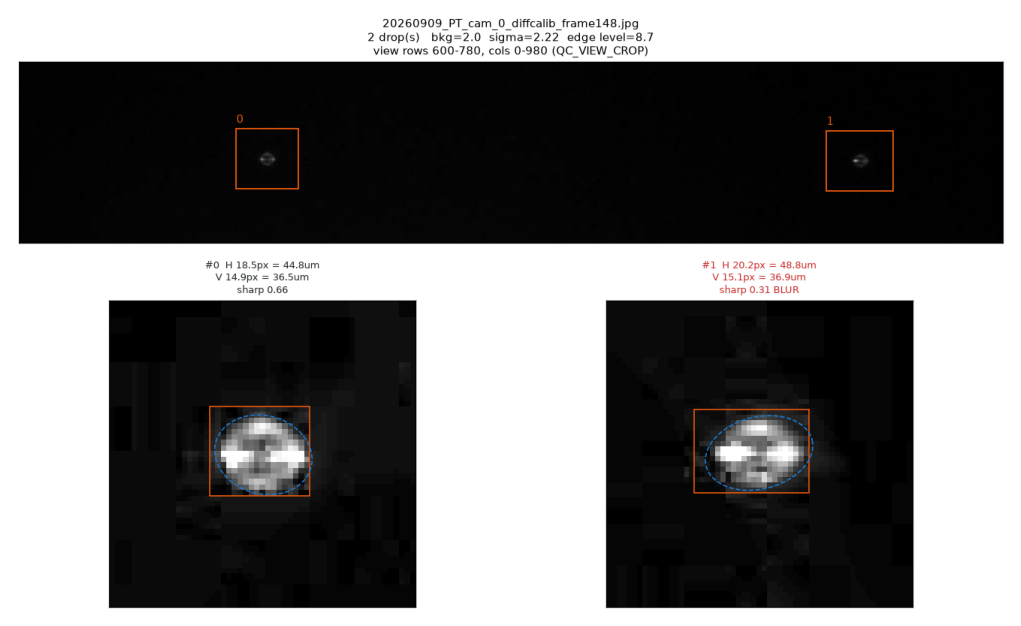

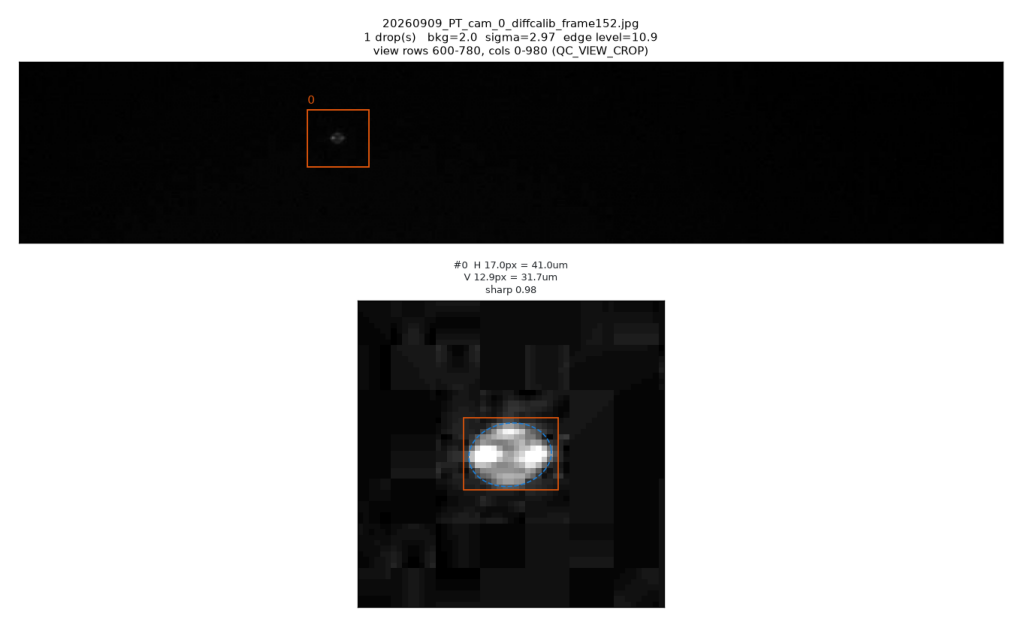

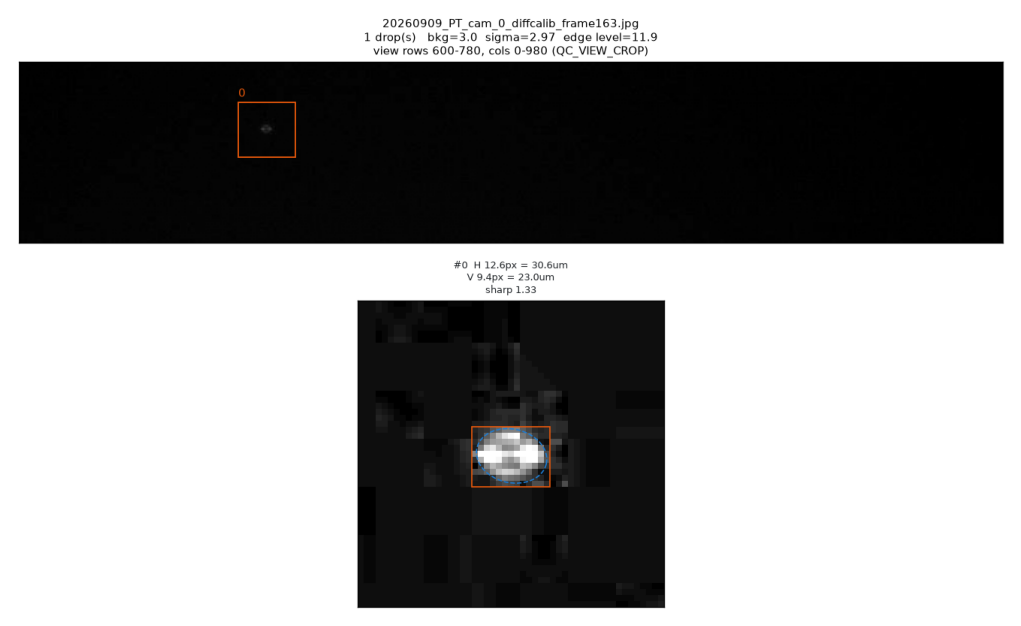

showed 3 of 6 overlays in F:\Imaging\2026.09.09\results\qc_drops


In [17]:
# ======================= Inline QC (quick eyeball) =======================
# Shows the first few saved overlays. Open results/qc_drops/ to review the whole batch.
#
# To zoom in on the drops, set QC_VIEW_CROP in the config cell and re-run the "DROPS: run over
# the folder" cell. Do NOT slice `img` here - these overlays are finished figures, so cropping
# one cuts off the titles and the H x V labels along with the empty space.
N_SHOW = 3

_qc = sorted(glob.glob(os.path.join(QC_DROPS_DIR, "*.png")))[:N_SHOW]
for p in _qc:
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(figsize=(13, 13 * img.shape[0] / img.shape[1]))
    ax.imshow(img); ax.set_xticks([]); ax.set_yticks([]); ax.set_frame_on(False)
    plt.show()
print(f"showed {len(_qc)} of "
      f"{len(glob.glob(os.path.join(QC_DROPS_DIR, '*.png')))} overlays in {QC_DROPS_DIR}")


## Acceptance checks

Run the cell below to check this notebook against the sample files the design was validated on.

In [18]:
# ======================= Acceptance checks =======================
# Re-measures the three validation drops and compares against INSTRUCTIONS.md section 8.

print("1. CALIBRATION  (target: X ~ 41.3 px/100um, Y ~ 40.9, RMS < 0.5, X vs Y within ~1%)")
_c = [r for r in CALIB["per_image"] if r["name"] == "20260909_PT_cam_21.png"]
if _c:
    r = _c[0]
    dxy = abs(r["px_per_box_x"] - r["px_per_box_y"]) / (0.5 * (r["px_per_box_x"] + r["px_per_box_y"]))
    print(f"   X {r['px_per_box_x']:.2f} px/100um ({BOX_UM/r['px_per_box_x']:.3f} um/px), "
          f"RMS {r['x']['rms']:.2f}")
    print(f"   Y {r['px_per_box_y']:.2f} px/100um ({BOX_UM/r['px_per_box_y']:.3f} um/px), "
          f"RMS {r['y']['rms']:.2f}")
    print(f"   X vs Y differ by {dxy:.2%}")
else:
    print("   (20260909_PT_cam_21.png not in the calibration folder - skipped)")

print("\n2. DROPS  (targets: f148 #0 H 17-20 / V 15-16 ; f148 #1 H ~24 BLUR ; f152 H 16-17 / V ~13)")
for _n in ["20260909_PT_cam_0_diffcalib_frame148.jpg",
           "20260909_PT_cam_0_diffcalib_frame152.jpg"]:
    sub = df[df["image"] == _n]
    if sub.empty:
        print(f"   ({_n} not in the drops folder - skipped)")
        continue
    print(f"   {_n}  ({int(sub['n_drops'].iloc[0])} drops)")
    for _, d in sub.iterrows():
        print(f"      #{int(d['drop_index'])}  H {d['H_px_subpx']:5.2f} px = {d['H_um']:5.1f} um   "
              f"V {d['V_px_subpx']:5.2f} px = {d['V_um']:5.1f} um   "
              f"blur={bool(d['blurry'])} sat={bool(d['saturated'])}")

print("\n3. Frame-edge artifacts absent, one QC overlay per image:")
print(f"   {len(glob.glob(os.path.join(QC_DROPS_DIR, '*.png')))} overlays / "
      f"{len(drop_files)} images")
print("   (check visually - no box should sit on the bright band at the top or bottom edge)")


1. CALIBRATION  (target: X ~ 41.3 px/100um, Y ~ 40.9, RMS < 0.5, X vs Y within ~1%)
   X 41.30 px/100um (2.421 um/px), RMS 0.26
   Y 40.82 px/100um (2.450 um/px), RMS 0.26
   X vs Y differ by 1.17%

2. DROPS  (targets: f148 #0 H 17-20 / V 15-16 ; f148 #1 H ~24 BLUR ; f152 H 16-17 / V ~13)
   20260909_PT_cam_0_diffcalib_frame148.jpg  (2 drops)
      #0  H 18.53 px =  44.8 um   V 14.91 px =  36.5 um   blur=False sat=False
      #1  H 20.17 px =  48.8 um   V 15.08 px =  36.9 um   blur=True sat=False
   20260909_PT_cam_0_diffcalib_frame152.jpg  (1 drops)
      #0  H 16.96 px =  41.0 um   V 12.94 px =  31.7 um   blur=False sat=False

3. Frame-edge artifacts absent, one QC overlay per image:
   6 overlays / 6 images
   (check visually - no box should sit on the bright band at the top or bottom edge)


## Diagnostics: is the drop ellipticity real, or an artifact?

The QC insets show the measured footprint clearly wider than tall (H/V ~ 1.3), while the small
far-view thumbnail of the same drop looks round. These four cells establish where that
elongation comes from. They are **read-only**: they re-measure and re-inspect, they never change
`K_SIGMA`, the top-hat kernel, the threshold, or any measurement logic, and nothing they compute
feeds `measurements.csv`.

Run them after the "DROPS: run over the folder" cell (they use `drop_files` and `measure_drops`).
They write `results/diagnostics_aspect.csv` and `results/diagnostics_ellipse.csv`.

| # | check | question it settles |
|---|---|---|
| 1 | RAW vs FLATTENED aspect | Is the elongation in the image data, or created by the top-hat background subtraction? |
| 2 | QC inset display | Can the display itself stretch a drop? |
| 3 | No-resampling audit | Does anything in the drop path rotate, warp or resize the image? |
| 4 | Ellipse angle | Does the elongation lie along the two side-by-side glare spots? |

### Findings on the 2026.09.09 `max zoom / trapping attempts` set (10 drops, 6 frames)

**The ellipticity is real and in the data.** Measured on the raw grayscale with no top-hat at
all, against a local background, aspect comes out **1.19 - 1.30 (median 1.26)** against the
flattened pipeline's 1.12 - 1.49 (median 1.31). All 10 drops read H > V in raw. Top-hat
subtraction inflates the aspect only slightly - about **0.07** in the median, because flattening
trims the low-contrast vertical shoulders a little more than the horizontal ones - but it does
not create the elongation.

**The display is faithful.** Every `imshow` is `aspect='equal'`, so pixels are never stretched.
Nothing in the drop path rotates, warps or resizes: `cv2.warpAffine` appears only in the
calibration de-rotation and `cv2.resize` appears nowhere in the notebook. The one real display
problem was that the per-drop inset crop window was sized off the bounding box, making the
*framing* as oblong as the drop - it is now square and centred on the centroid (see the note in
`save_drop_qc`). That was a display change only; the measurements are unchanged.

**The orientation matches the glare geometry.** All 10 fitted major axes sit within 15 deg of
horizontal (median 9.6 deg), aligned with the line joining the two specular spots.

**Why the far-view thumbnail looks round:** at that scale a 1.3 aspect on a ~15 px object is a
couple of pixels. The square inset now shows the same shape the numbers report.

**This is a measurement of the specular footprint, not proof of a non-spherical droplet.** A
trapped droplet is round; what is elongated is the bright region the two glare spots and the
faint ring produce. Treat `H_um` and `V_um` accordingly, and do not "correct" the vertical
number to close the gap - see **Things not to do** in the tuning guide above.


In [19]:
# ============ DIAGNOSTIC 1: RAW vs FLATTENED aspect - the decisive check ============
# Measures H and V a second time on the RAW grayscale (no top-hat at all), using the same
# `background + K_SIGMA * sigma` edge criterion but with the background estimated locally, in
# a box around each drop with the drop's own footprint masked out. If aspect_raw tracks
# aspect_flat, the elongation is in the data (glare geometry) and the top-hat is not creating
# it. READ-ONLY: nothing here feeds measurements.csv, and K_SIGMA is used exactly as set.
#
# Two columns of raw aspect are reported, because one of them can degenerate:
#   asp_raw     - local median + K_SIGMA * local sigma. The honest like-for-like number, but
#                 on JPEG frames the local raw background is sometimes perfectly flat, its
#                 robust sigma quantises to 0, and the level collapses onto the background
#                 itself. Those rows are flagged and must not be read.
#   asp_raw_kf  - local median + K_SIGMA * sigma_flat, i.e. the same *absolute* contrast
#                 offset in counts that the flattened pipeline is using on that frame,
#                 above the local raw background. Needs no local sigma, so it survives the
#                 flat-background rows and is the fallback for them.

ASPECT_HALO = 14     # px the drop footprint is dilated by before it is excluded from the background
ASPECT_RING = 26     # px of extra margin around that, defining the local background box


def _walk_to_level(profile, anchor, step, level, max_walk=40):
    """Sub-pixel position where `profile` crosses `level`, searching from `anchor` in the
    direction `step` (-1 = left/up, +1 = right/down).

    Same criterion as the pipeline's `_refine_edges` - anchored on the blob, linearly
    interpolated between the two straddling samples - but allowed to travel further than one
    sample. The raw image needs that: its edge does not sit within 1 px of the boundary of the
    blob found on the flattened image. Returns (position, crossing_found)."""
    p = np.asarray(profile, float)
    n = len(p)
    if p[anchor] >= level:                       # inside the drop: travel outward
        i = anchor
        for _ in range(max_walk):
            j = i + step
            if not (0 <= j < n) or p[j] < level:
                break
            i = j
    else:                                        # already outside: travel back inward
        i = anchor
        for _ in range(max_walk):
            j = i - step
            if not (0 <= j < n):
                break
            i = j
            if p[i] >= level:
                break
        if p[i] < level:
            return anchor + step * 0.5, False
    j = i + step
    if 0 <= j < n and p[j] < level <= p[i]:
        return i + step * (p[i] - level) / (p[i] - p[j]), True
    return i + step * 0.5, False                 # ran off the profile without crossing


def measure_extent(profile, i_first, i_last, level):
    """(width, both_edges_found) along one line, from the blob's first/last pixel on it."""
    lo, ok_lo = _walk_to_level(profile, i_first, -1, level)
    hi, ok_hi = _walk_to_level(profile, i_last, +1, level)
    return hi - lo, (ok_lo and ok_hi)


def local_background(img, cx, cy, bw, bh, footprint):
    """Robust (median, sigma) of `img` in a box around one drop, that drop's footprint
    (dilated by ASPECT_HALO) excluded. Same robust-sigma rule `background_stats` uses, so the
    raw and flattened thresholds are built the same way."""
    H, W = img.shape
    ry = int(bh / 2 + ASPECT_HALO + ASPECT_RING)
    rx = int(bw / 2 + ASPECT_HALO + ASPECT_RING)
    y0, y1 = max(0, int(cy) - ry), min(H, int(cy) + ry + 1)
    x0, x1 = max(0, int(cx) - rx), min(W, int(cx) + rx + 1)
    win = img[y0:y1, x0:x1]
    k = 2 * ASPECT_HALO + 1
    excl = cv2.dilate(footprint[y0:y1, x0:x1].astype(np.uint8),
                      cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))) > 0
    v = win[~excl].ravel()
    if v.size < 50:                              # pathologically crowded box; use all of it
        v = win.ravel()
    med = float(np.median(v))
    mad_sigma = 1.4826 * float(np.median(np.abs(v - med)))
    iqr_sigma = float(np.percentile(v, 75) - np.percentile(v, 25)) / 1.349
    return med, max(mad_sigma, iqr_sigma, 1e-6)


def drop_footprints(diag):
    """Re-derive the per-component footprint masks exactly as `measure_drops` does, so each
    measured drop can be paired with the mask it was measured from. `measure_drops` builds
    these internally and does not return them; the assertion below checks the re-derivation
    reproduces the same centroid and bbox, so a future edit to the detection cannot silently
    desynchronise this diagnostic from the measurement."""
    flat, level = diag["flat"], diag["level"]
    Himg, Wimg = flat.shape
    mask = binary_fill_holes(flat > level)
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_CLOSE,
                            _CLOSE_SE, iterations=CLOSE_ITER)
    mask = binary_fill_holes(mask.astype(bool))
    labels, _ = label(mask)
    out = []
    for i, sl in enumerate(find_objects(labels)):
        if sl is None:
            continue
        comp = (labels[sl] == i + 1)
        area = int(comp.sum())
        if area < MIN_DROP_AREA or area > MAX_DROP_AREA:
            continue
        y0, y1, x0, x1 = sl[0].start, sl[0].stop, sl[1].start, sl[1].stop
        if (x0 < EDGE_MARGIN or y0 < EDGE_MARGIN
                or x1 > Wimg - EDGE_MARGIN or y1 > Himg - EDGE_MARGIN):
            continue
        ys, xs = np.nonzero(comp)
        full = np.zeros((Himg, Wimg), bool)
        full[sl][comp] = True
        out.append({"cx": x0 + float(xs.mean()), "cy": y0 + float(ys.mean()),
                    "bbox": (x0, y0, x1, y1), "full": full})
    return out


def major_axis_from_cv_ellipse(ellipse):
    """cv2.fitEllipse output -> (major_len, minor_len, degrees_from_horizontal).

    0 deg = major axis horizontal, +-90 = vertical. Taken from cv2.boxPoints so the
    width/height/angle convention cannot be misread: OpenCV does not guarantee that the
    second size is the major axis, nor is the angle's sense obvious under a y-down image."""
    (cx, cy), (w, h), ang = ellipse
    if not (np.isfinite(w) and np.isfinite(h)):
        return np.nan, np.nan, np.nan
    pts = cv2.boxPoints(((cx, cy), (w, h), ang))
    e1, e2 = pts[1] - pts[0], pts[2] - pts[1]
    maj, mnr = (e1, e2) if np.hypot(*e1) >= np.hypot(*e2) else (e2, e1)
    theta = math.degrees(math.atan2(-maj[1], maj[0])) % 180.0     # -y: image rows grow downward
    return float(np.hypot(*maj)), float(np.hypot(*mnr)), float(theta - 180.0 if theta > 90 else theta)


# ------------------------------------------------------------------ run
ASPECT_DIAG = []
print(f"RAW vs FLATTENED aspect     K_SIGMA = {K_SIGMA}  (unchanged), "
      f"TOPHAT_KERNEL = {TOPHAT_KERNEL}")
print("=" * 116)

for _path in drop_files:
    _name = os.path.basename(_path)
    _drops, _diag = measure_drops(_path)
    if not _drops:
        print(f"{_name}: 0 drops")
        continue
    _raw, _flat = _diag["raw"], _diag["flat"]
    _prints = drop_footprints(_diag)

    print(f"\n{_name}    flat bkg med={_diag['med']:.2f}  sigma={_diag['sigma']:.3f}  "
          f"edge level={_diag['level']:.2f}")
    print(f"  {'#':>2} {'H_flat':>7} {'V_flat':>7} {'asp_flat':>9} | "
          f"{'H_raw':>7} {'V_raw':>7} {'asp_raw':>8} {'asp_raw_kf':>11} | "
          f"{'rawbkg':>7} {'rawsig':>7} | {'d(asp)':>7}")
    for _d in _drops:
        _m = min(_prints, key=lambda p: (p["cx"] - _d["centroid_x"]) ** 2
                                        + (p["cy"] - _d["centroid_y"]) ** 2)
        assert abs(_m["cx"] - _d["centroid_x"]) < 1e-9 and _m["bbox"] == _d["bbox"], (
            "footprint re-derivation no longer matches measure_drops - the detection code "
            "changed and this diagnostic must be updated before its numbers are trusted")
        _full = _m["full"]
        _x0, _y0, _x1, _y1 = _d["bbox"]
        _r, _c = int(round(_d["centroid_y"])), int(round(_d["centroid_x"]))
        _rowi = np.flatnonzero(_full[_r, :])
        _coli = np.flatnonzero(_full[:, _c])

        # (a) flattened, same criterion, same walk - a method-parity control. Any gap between
        #     this and H_flat/V_flat is the multi-pixel walk, not the raw-vs-flat question.
        _Hfw, _ = measure_extent(_flat[_r, :], _rowi[0], _rowi[-1], _diag["level"])
        _Vfw, _ = measure_extent(_flat[:, _c], _coli[0], _coli[-1], _diag["level"])

        # (b) raw, local background + K_SIGMA * local sigma
        _bmed, _bsig = local_background(_raw, _d["centroid_x"], _d["centroid_y"],
                                        _x1 - _x0, _y1 - _y0, _full)
        _lvl = _bmed + K_SIGMA * _bsig
        _Hr, _okh = measure_extent(_raw[_r, :], _rowi[0], _rowi[-1], _lvl)
        _Vr, _okv = measure_extent(_raw[:, _c], _coli[0], _coli[-1], _lvl)

        # (c) raw at the flattened frame's own absolute contrast offset - no local sigma
        _lvl_kf = _bmed + K_SIGMA * _diag["sigma"]
        _Hk, _ = measure_extent(_raw[_r, :], _rowi[0], _rowi[-1], _lvl_kf)
        _Vk, _ = measure_extent(_raw[:, _c], _coli[0], _coli[-1], _lvl_kf)

        _Hf, _Vf = _d["H_px_subpx"], _d["V_px_subpx"]
        _af = _Hf / _Vf
        _ar = _Hr / _Vr if _Vr > 0 else np.nan
        _ak = _Hk / _Vk if _Vk > 0 else np.nan
        _degen = _bsig < 1e-3
        print(f"  {_d['drop_index']:>2} {_Hf:7.2f} {_Vf:7.2f} {_af:9.3f} | "
              f"{_Hr:7.2f} {_Vr:7.2f} {_ar:8.3f} {_ak:11.3f} | "
              f"{_bmed:7.2f} {_bsig:7.3f} | {_ar - _af:+7.3f}"
              + ("   * local raw sigma quantised to 0 - read asp_raw_kf" if _degen else ""))

        ASPECT_DIAG.append({
            "image": _name, "drop_index": _d["drop_index"],
            "H_flat": _Hf, "V_flat": _Vf, "aspect_flat": _af,
            "H_flat_walk": _Hfw, "V_flat_walk": _Vfw, "aspect_flat_walk": _Hfw / _Vfw,
            "H_raw": _Hr, "V_raw": _Vr, "aspect_raw": _ar,
            "H_raw_kf": _Hk, "V_raw_kf": _Vk, "aspect_raw_kf": _ak,
            "raw_bkg": _bmed, "raw_sigma": _bsig, "raw_level": _lvl,
            "raw_sigma_degenerate": bool(_degen),
            "both_raw_edges_found": bool(_okh and _okv),
            "flat_sigma": _diag["sigma"], "flat_level": _diag["level"],
            "k_sigma": K_SIGMA, "ellipse": _d["ellipse"],
        })

ASPECT_DF = pd.DataFrame([{k: v for k, v in r.items() if k != "ellipse"}
                          for r in ASPECT_DIAG])

# ------------------------------------------------------------------ summary
_ok = ~ASPECT_DF["raw_sigma_degenerate"]
print("\n" + "=" * 116)
print("METHOD-PARITY CONTROL  (the same multi-pixel walk applied to the FLAT image)")
print(f"  {'image':<44}{'#':>3}{'asp_flat':>10}{'asp_flat_walk':>15}"
      f"{'asp_raw':>10}{'asp_raw_kf':>12}")
for _, _d in ASPECT_DF.iterrows():
    print(f"  {_d['image']:<44}{int(_d['drop_index']):>3}{_d['aspect_flat']:10.3f}"
          f"{_d['aspect_flat_walk']:15.3f}{_d['aspect_raw']:10.3f}{_d['aspect_raw_kf']:12.3f}"
          + ("  *" if _d["raw_sigma_degenerate"] else ""))
print("  A gap between asp_flat and asp_flat_walk is the walk length, not the background")
print("  subtraction - it bounds how much of d(asp) is method rather than data.")

print("\n" + "=" * 116)
print("SUMMARY")
print(f"  all {len(ASPECT_DF)} drops       : median asp_flat {ASPECT_DF['aspect_flat'].median():.3f}"
      f"   asp_raw_kf {ASPECT_DF['aspect_raw_kf'].median():.3f}")
print(f"  {int(_ok.sum())} with usable raw sigma : "
      f"median asp_flat {ASPECT_DF.loc[_ok, 'aspect_flat'].median():.3f}"
      f"   asp_raw {ASPECT_DF.loc[_ok, 'aspect_raw'].median():.3f}"
      f"   median |asp_raw - asp_flat| "
      f"{(ASPECT_DF.loc[_ok, 'aspect_raw'] - ASPECT_DF.loc[_ok, 'aspect_flat']).abs().median():.3f}")
print(f"  asp_raw    range (usable sigma) : {ASPECT_DF.loc[_ok, 'aspect_raw'].min():.3f} .. "
      f"{ASPECT_DF.loc[_ok, 'aspect_raw'].max():.3f}")
print(f"  asp_raw_kf range (all drops)    : {ASPECT_DF['aspect_raw_kf'].min():.3f} .. "
      f"{ASPECT_DF['aspect_raw_kf'].max():.3f}")
print(f"  drops reading H > V : flat {int((ASPECT_DF['aspect_flat'] > 1).sum())}"
      f"/{len(ASPECT_DF)}   raw_kf {int((ASPECT_DF['aspect_raw_kf'] > 1).sum())}"
      f"/{len(ASPECT_DF)}")
if int((~_ok).sum()):
    print(f"  * {int((~_ok).sum())} drop(s) sat on a JPEG-flat local background (raw sigma -> 0); "
          f"their asp_raw is meaningless.")
print("\nINTERPRETATION")
print("  asp_raw close to asp_flat  => the elongation is in the image data, i.e. the glare")
print("  geometry. The top-hat is not creating it. Do NOT retune K_SIGMA on the strength of")
print("  this; see the 'Things not to do' list in the tuning guide above.")
print("  asp_raw ~ 1 while asp_flat > 1 would be the opposite finding: an artifact of the")
print("  background subtraction, and only then is the flattening worth revisiting.")

_asp_csv = os.path.join(RESULTS_DIR, "diagnostics_aspect.csv")
ASPECT_DF.to_csv(_asp_csv, index=False)
print("\nwrote", _asp_csv)

with pd.option_context("display.width", 240, "display.max_columns", 40,
                       "display.float_format", lambda v: f"{v:.3f}"):
    display(ASPECT_DF[["image", "drop_index", "H_flat", "V_flat", "aspect_flat",
                       "H_raw", "V_raw", "aspect_raw", "aspect_raw_kf",
                       "raw_sigma", "raw_sigma_degenerate"]])


RAW vs FLATTENED aspect     K_SIGMA = 3.0  (unchanged), TOPHAT_KERNEL = 61

20260909_PT_cam_0_diffcalib_frame148.jpg    flat bkg med=2.00  sigma=2.224  edge level=8.67
   #  H_flat  V_flat  asp_flat |   H_raw   V_raw  asp_raw  asp_raw_kf |  rawbkg  rawsig |  d(asp)
   0   18.53   14.91     1.243 |   18.74   15.20    1.233       1.236 |   32.00   1.483 |  -0.011
   1   20.17   15.08     1.337 |   22.25   17.61    1.264       1.253 |   29.00   0.741 |  -0.074

20260909_PT_cam_0_diffcalib_frame152.jpg    flat bkg med=2.00  sigma=2.965  edge level=10.90
   #  H_flat  V_flat  asp_flat |   H_raw   V_raw  asp_raw  asp_raw_kf |  rawbkg  rawsig |  d(asp)
   0   16.96   12.94     1.311 |   20.59   16.47    1.250       1.312 |   30.00   1.483 |  -0.061

20260909_PT_cam_0_diffcalib_frame163.jpg    flat bkg med=3.00  sigma=2.965  edge level=11.90
   #  H_flat  V_flat  asp_flat |   H_raw   V_raw  asp_raw  asp_raw_kf |  rawbkg  rawsig |  d(asp)
   0   12.64    9.40     1.345 |   15.65   13.18    1.18

,image,drop_index,H_flat,V_flat,aspect_flat,H_raw,V_raw,aspect_raw,aspect_raw_kf,raw_sigma,raw_sigma_degenerate
0,20260909_PT_cam_0_diffcalib_frame148.jpg,0,18.534,14.906,1.243,18.737,15.199,1.233,1.236,1.483,False
1,20260909_PT_cam_0_diffcalib_frame148.jpg,1,20.166,15.078,1.337,22.254,17.608,1.264,1.253,0.741,False
2,20260909_PT_cam_0_diffcalib_frame152.jpg,0,16.961,12.937,1.311,20.587,16.473,1.250,1.312,1.483,False
3,20260909_PT_cam_0_diffcalib_frame163.jpg,0,12.641,9.397,1.345,15.647,13.180,1.187,1.345,0.741,False
4,20260909_PT_cam_0_diffcalib_frame372.jpg,0,16.707,13.939,1.199,27.000,24.000,1.125,1.190,0.000,True
5,20260909_PT_cam_0_diffcalib_frame372.jpg,1,22.190,14.898,1.489,21.242,16.416,1.294,1.332,0.741,False
6,20260909_PT_cam_0_diffcalib_frame372.jpg,2,17.420,12.404,1.404,20.049,15.720,1.275,1.240,0.741,False
7,20260909_PT_cam_0_diffcalib_frame378j.jpg,0,14.297,12.795,1.117,29.000,20.000,1.450,1.112,0.000,True
8,20260909_PT_cam_0_diffcalib_frame378j.jpg,1,13.164,10.331,1.274,16.084,12.375,1.300,1.274,0.741,False
9,20260909_PT_cam_0_diffcalib_frame379.jpg,0,15.677,12.064,1.299,19.056,19.500,0.977,1.299,0.000,True


In [20]:
# ================ DIAGNOSTIC 4: fitEllipse orientation and axis lengths ================
# If the footprint is elongated by the two side-by-side specular spots, the fitted major axis
# must come out near-HORIZONTAL. A major axis near vertical, or scattered at random angles,
# would mean the elongation is not the glare geometry and needs a different explanation.
#
# The angle is derived from cv2.boxPoints rather than read off fitEllipse's (width, height,
# angle) triple: OpenCV does not guarantee which of the two sizes is the major axis, so
# reading the convention directly is a real source of error. Report only.

_diag_ell = []
for _r in ASPECT_DIAG:
    _maj, _min, _theta = major_axis_from_cv_ellipse(_r["ellipse"])
    (_ex, _ey), (_w, _h), _ang = _r["ellipse"]
    _diag_ell.append({
        "image": _r["image"], "drop_index": _r["drop_index"],
        "ellipse_major_px": _maj, "ellipse_minor_px": _min,
        "ellipse_ratio": _maj / _min if _min else np.nan,
        "deg_from_horizontal": _theta,
        "cv2_size_w": _w, "cv2_size_h": _h, "cv2_angle_deg": _ang,
        # Does the notebook's `(minor, major) = fitEllipse(...)[1]` unpacking hold here?
        "cv2_order_ok": bool(_h >= _w),
    })

ELLIPSE_DIAG = pd.DataFrame(_diag_ell)

print("fitEllipse orientation   (0 deg = major axis horizontal, +-90 = vertical)")
print("=" * 104)
print(f"{'image':<44}{'#':>3}{'major':>8}{'minor':>8}{'maj/min':>9}"
      f"{'deg_from_horiz':>16}{'cv2 (w, h, ang)':>24}")
for _, _d in ELLIPSE_DIAG.iterrows():
    _cv = f"({_d['cv2_size_w']:.2f}, {_d['cv2_size_h']:.2f}, {_d['cv2_angle_deg']:.1f})"
    print(f"{_d['image']:<44}{int(_d['drop_index']):>3}"
          f"{_d['ellipse_major_px']:8.2f}{_d['ellipse_minor_px']:8.2f}"
          f"{_d['ellipse_ratio']:9.3f}{_d['deg_from_horizontal']:+16.1f}{_cv:>24}")

_th = ELLIPSE_DIAG["deg_from_horizontal"].abs()
print("\n" + "-" * 104)
print(f"|angle from horizontal| : median {_th.median():.1f} deg, max {_th.max():.1f} deg, "
      f"{int((_th <= 30).sum())}/{len(_th)} within 30 deg of horizontal")
print(f"ellipse major/minor    : median {ELLIPSE_DIAG['ellipse_ratio'].median():.3f}")
print("\nINTERPRETATION")
print("  Major axis clustered near 0 deg  => elongation lies along the line joining the two")
print("  glare spots, i.e. it is the specular geometry, exactly as expected.")
print("  Major axis near +-90 deg, or scattered => something else is elongating the footprint.")

if not ELLIPSE_DIAG["cv2_order_ok"].all():
    _bad = ELLIPSE_DIAG.loc[~ELLIPSE_DIAG["cv2_order_ok"], ["image", "drop_index"]]
    print("\n  !! WARNING: cv2.fitEllipse returned width > height for the drop(s) below, so the")
    print("     pipeline's `(minor, major) = fitEllipse(...)[1]` unpacking has them SWAPPED and")
    print("     the CSV's ellipse_major_px / ellipse_minor_px are mislabelled for those rows.")
    print("     H_px_subpx / V_px_subpx are unaffected - they never touch the ellipse fit.")
    print(_bad.to_string(index=False))
else:
    print(f"\n  cv2.fitEllipse returned height >= width for all {len(ELLIPSE_DIAG)} drops, so the")
    print("  pipeline's `(minor, major)` unpacking is correctly ordered for this batch. That")
    print("  ordering is NOT guaranteed by OpenCV, hence the check - it is re-tested every run.")

_ell_csv = os.path.join(RESULTS_DIR, "diagnostics_ellipse.csv")
ELLIPSE_DIAG.to_csv(_ell_csv, index=False)
print("\nwrote", _ell_csv)

with pd.option_context("display.width", 220, "display.max_columns", 40,
                       "display.float_format", lambda v: f"{v:.3f}"):
    display(ELLIPSE_DIAG)


fitEllipse orientation   (0 deg = major axis horizontal, +-90 = vertical)
image                                         #   major   minor  maj/min  deg_from_horiz         cv2 (w, h, ang)
20260909_PT_cam_0_diffcalib_frame148.jpg      0   17.67   14.06    1.257           -14.7   (14.06, 17.67, 104.7)
20260909_PT_cam_0_diffcalib_frame148.jpg      1   21.01   13.86    1.515           +13.7    (13.86, 21.01, 76.3)
20260909_PT_cam_0_diffcalib_frame152.jpg      0   14.87   11.33    1.312            +7.7    (11.33, 14.87, 82.3)
20260909_PT_cam_0_diffcalib_frame163.jpg      0   11.84    8.92    1.328           -13.0    (8.92, 11.84, 103.0)
20260909_PT_cam_0_diffcalib_frame372.jpg      0   14.98   12.95    1.157            -7.9    (12.95, 14.98, 97.9)
20260909_PT_cam_0_diffcalib_frame372.jpg      1   21.55   15.40    1.399           +12.1    (15.40, 21.55, 77.9)
20260909_PT_cam_0_diffcalib_frame372.jpg      2   16.14   10.92    1.478            +5.5    (10.92, 16.14, 84.5)
20260909_PT_cam_0_diff

,image,drop_index,ellipse_major_px,ellipse_minor_px,ellipse_ratio,deg_from_horizontal,cv2_size_w,cv2_size_h,cv2_angle_deg,cv2_order_ok
0,20260909_PT_cam_0_diffcalib_frame148.jpg,0,17.670,14.059,1.257,-14.691,14.059,17.670,104.691,True
1,20260909_PT_cam_0_diffcalib_frame148.jpg,1,21.008,13.864,1.515,13.736,13.864,21.008,76.264,True
2,20260909_PT_cam_0_diffcalib_frame152.jpg,0,14.874,11.333,1.312,7.675,11.333,14.874,82.326,True
3,20260909_PT_cam_0_diffcalib_frame163.jpg,0,11.841,8.916,1.328,-13.039,8.916,11.841,103.039,True
4,20260909_PT_cam_0_diffcalib_frame372.jpg,0,14.981,12.954,1.157,-7.936,12.954,14.981,97.937,True
5,20260909_PT_cam_0_diffcalib_frame372.jpg,1,21.548,15.403,1.399,12.123,15.403,21.548,77.877,True
6,20260909_PT_cam_0_diffcalib_frame372.jpg,2,16.145,10.921,1.478,5.495,10.921,16.145,84.505,True
7,20260909_PT_cam_0_diffcalib_frame378j.jpg,0,14.154,11.526,1.228,4.212,11.526,14.154,85.788,True
8,20260909_PT_cam_0_diffcalib_frame378j.jpg,1,11.605,9.038,1.284,2.790,9.038,11.605,87.210,True
9,20260909_PT_cam_0_diffcalib_frame379.jpg,0,15.852,10.275,1.543,11.319,10.275,15.852,78.681,True


In [21]:
# ============ DIAGNOSTIC 2 + 3: display faithfulness and no-resampling audit ============
# CHECK 2: the QC panels must not be able to stretch a drop.
# CHECK 3: nothing in the drop path may rotate, warp or resize the image - not directly, and
#          not by calling a helper that does.
# Both re-verify on every run, by inspecting the live figure and the live source, so they stay
# honest if someone later edits `save_drop_qc` or `measure_drops`.

import inspect, io, tokenize, textwrap, tempfile

print("=" * 96)
print("CHECK 2 - QC display cannot stretch a drop")
print("=" * 96)
print("matplotlib defaults:")
for _k in ("image.aspect", "image.interpolation", "image.origin"):
    print(f"   rcParams[{_k!r}] = {matplotlib.rcParams[_k]!r}")
print("   ('equal' is what we need; 'auto' would stretch pixels to fill the axes.)")

# --- the inset crop window must be SQUARE: equal +-half px in x and y around the centroid.
print("\ninset crop windows (recomputed the way save_drop_qc builds them):")
_all_square = True
for _path in drop_files:
    _drops, _diag = measure_drops(_path)
    for _d in _drops:
        _x0, _y0, _x1, _y1 = _d["bbox"]
        _cx, _cy = int(round(_d["centroid_x"])), int(round(_d["centroid_y"]))
        _half = int(np.ceil(max(_x1 - _x0, _y1 - _y0) / 2)) + 18
        _half = max(1, min(_half, _cx, _cy,
                           _diag["raw"].shape[1] - 1 - _cx, _diag["raw"].shape[0] - 1 - _cy))
        _w = _h = 2 * _half + 1
        _all_square &= (_w == _h)
        print(f"   {os.path.basename(_path):<44}#{_d['drop_index']}  "
              f"window {_w:>3} x {_h:<3} px   (bbox {_x1-_x0:>2} x {_y1-_y0:<2})   "
              f"square: {_w == _h}")
print(f"\n   all inset windows square: {_all_square}")

# --- and the axes actually drawn must be aspect-equal. Inspect a real overlay figure.
_path = drop_files[0]
_drops, _diag = measure_drops(_path)
_made, _orig_figure = [], plt.figure
def _capture(*a, **k):
    _f = _orig_figure(*a, **k)
    _made.append(_f)
    return _f
plt.figure = _capture
try:
    with tempfile.TemporaryDirectory() as _td:
        save_drop_qc(_path, _drops, _diag, scale_x, scale_y, os.path.join(_td, "probe.png"))
finally:
    plt.figure = _orig_figure

print(f"\naxes actually drawn in the overlay for {os.path.basename(_path)}:")
_aspects = []
for _ax in _made[-1].axes:
    for _im in _ax.get_images():
        _arr = _im.get_array()
        _aspects.append(_ax.get_aspect())
        _kind = ("inset" if _arr.shape[0] == _arr.shape[1] and max(_arr.shape) < 200
                 else "full-frame view")
        print(f"   {_arr.shape[0]:>4} x {_arr.shape[1]:<4} px   aspect={_ax.get_aspect()!r:<6} "
              f"interpolation={_im.get_interpolation()!r:<10} <- {_kind}"
              + ("  SQUARE" if _arr.shape[0] == _arr.shape[1] else ""))
plt.close(_made[-1])
_all_equal_aspect = all(a == 1.0 or a == "equal" for a in _aspects)
print(f"\n   every panel aspect-equal: {_all_equal_aspect}"
      "  => a round drop cannot render as elliptical.")


print("\n" + "=" * 96)
print("CHECK 3 - no rotation / warp / resize anywhere in the drop path")
print("=" * 96)
_RESAMPLERS = ("warpAffine", "warpPerspective", "getRotationMatrix2D", "cv2.resize",
               "cv2.remap", "rot90", "np.transpose", "cv2.pyrDown", "cv2.pyrUp")
_ROTATION_HELPERS = ("rotate_image",)     # the notebook's own wrapper around warpAffine
_DROP_PATH  = [load_gray, flatten, background_stats, _refine_edges, measure_drops,
               view_window, save_drop_qc, stretch_for_display]
_CALIB_PATH = [rotate_image, derotate, find_grid_roi, spacing_from_profile,
               measure_calibration_image, save_calibration_qc, calibrate_folder]


def _code_only_lines(fn):
    """{line number: code on that line with comments and string literals removed}.

    Comments and docstrings name these functions on purpose - including this notebook's own
    'warpAffine appears only in the calibration de-rotation' note - and a mention is not a
    call. Tokenising and dropping COMMENT/STRING tokens is what separates the two."""
    src = textwrap.dedent(inspect.getsource(fn))
    out = {}
    for tok in tokenize.generate_tokens(io.StringIO(src).readline):
        if tok.type in (tokenize.COMMENT, tokenize.STRING, tokenize.NL, tokenize.NEWLINE):
            continue
        out.setdefault(tok.start[0], []).append(tok.string)
    return {ln: "".join(t) for ln, t in out.items()}, src.splitlines()


def _scan(fns, needles):
    """Every line that actually *calls* one of `needles`. `def` lines are skipped so a
    helper does not report itself, and comments/docstrings are already gone."""
    hits = []
    for fn in fns:
        code, lines = _code_only_lines(fn)
        for ln in sorted(code):
            if code[ln].startswith("def"):
                continue
            for needle in needles:
                if needle in code[ln]:
                    hits.append((fn.__name__, ln, needle, lines[ln - 1].strip()))
    return hits


_drop_direct   = _scan(_DROP_PATH, _RESAMPLERS)
_drop_indirect = _scan(_DROP_PATH, _ROTATION_HELPERS)
_cal_direct    = _scan(_CALIB_PATH, _RESAMPLERS)
_cal_indirect  = _scan(_CALIB_PATH, _ROTATION_HELPERS)

print("DROP path   (" + ", ".join(f.__name__ for f in _DROP_PATH) + ")")
print("  direct resampling calls:")
if _drop_direct:
    for nm, ln, tok, line in _drop_direct:
        print(f"     !! {nm} line {ln}: {tok}   {line}")
else:
    print("     none")
print("  calls to a rotating helper:")
if _drop_indirect:
    for nm, ln, tok, line in _drop_indirect:
        print(f"     !! {nm} line {ln}: {tok}   {line}")
else:
    print("     none")
if not _drop_direct and not _drop_indirect:
    print("  => clean. Drops are detected and measured on the pixel grid they were captured")
    print("     on, so no interpolation can distort their shape.")

print("\nCALIBRATION path   (" + ", ".join(f.__name__ for f in _CALIB_PATH) + ")")
for nm, ln, tok, line in _cal_direct + _cal_indirect:
    print(f"   {nm} line {ln}: {tok}")
    print(f"      {line}")
print("   (expected: the grid de-rotation, and only there.)")

_resample_free = not (_drop_direct or _drop_indirect)
print(f"\nVERDICT   check 2: display faithful = {bool(_all_square and _all_equal_aspect)}"
      f"   |   check 3: drop path resampling-free = {_resample_free}")


CHECK 2 - QC display cannot stretch a drop
matplotlib defaults:
   rcParams['image.aspect'] = 'equal'
   rcParams['image.interpolation'] = 'auto'
   rcParams['image.origin'] = 'upper'
   ('equal' is what we need; 'auto' would stretch pixels to fill the axes.)

inset crop windows (recomputed the way save_drop_qc builds them):
   20260909_PT_cam_0_diffcalib_frame148.jpg    #0  window  55 x 55  px   (bbox 18 x 16)   square: True
   20260909_PT_cam_0_diffcalib_frame148.jpg    #1  window  59 x 59  px   (bbox 22 x 16)   square: True
   20260909_PT_cam_0_diffcalib_frame152.jpg    #0  window  55 x 55  px   (bbox 17 x 13)   square: True
   20260909_PT_cam_0_diffcalib_frame163.jpg    #0  window  51 x 51  px   (bbox 13 x 10)   square: True
   20260909_PT_cam_0_diffcalib_frame372.jpg    #0  window  55 x 55  px   (bbox 17 x 14)   square: True
   20260909_PT_cam_0_diffcalib_frame372.jpg    #1  window  61 x 61  px   (bbox 24 x 19)   square: True
   20260909_PT_cam_0_diffcalib_frame372.jpg    #2  wind